In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("emails.csv")

print(df.head())
print(df.shape)
print(df.info())

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
(5172, 3002)
<class 'pandas.core.frame.DataFrame'>
RangeIndex:

In [3]:
df = df.drop("Email No.", axis=1)

print(df.isnull().sum().sum())

X = df.drop("Prediction", axis=1)
y = df["Prediction"]

print("Features:", X.shape)
print("Target:", y.shape)

print(y.value_counts())

0
Features: (5172, 3000)
Target: (5172,)
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4137, 3000)
Testing data: (1035, 3000)


In [5]:
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

start = time.time()

knn.fit(X_train, y_train)

knn_train_time = time.time() - start

start = time.time()

y_pred_knn = knn.predict(X_test)

knn_test_time = time.time() - start

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_knn,
    target_names=["Not Spam", "Spam"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN Accuracy: 0.8338164251207729

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035

Confusion Matrix:
[[576 159]
 [ 13 287]]


In [6]:
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="linear", C=1))
])

start = time.time()

svm.fit(X_train, y_train)

svm_train_time = time.time() - start

start = time.time()

y_pred_svm = svm.predict(X_test)

svm_test_time = time.time() - start

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_svm,
    target_names=["Not Spam", "Spam"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM Accuracy: 0.9507246376811594

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035

Confusion Matrix:
[[709  26]
 [ 25 275]]


In [7]:
results = pd.DataFrame({
    "Algorithm": ["KNN", "SVM"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],

    "Precision": [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm)
    ],

    "Recall": [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm)
    ],

    "Training Time": [
        knn_train_time,
        svm_train_time
    ],

    "Testing Time": [
        knn_test_time,
        svm_test_time
    ]
})

print(results)

  Algorithm  Accuracy  Precision    Recall  F1 Score  Training Time  \
0       KNN  0.833816   0.643498  0.956667  0.769437       1.065611   
1       SVM  0.950725   0.913621  0.916667  0.915141       8.580116   

   Testing Time  
0      4.681357  
1      1.735217  


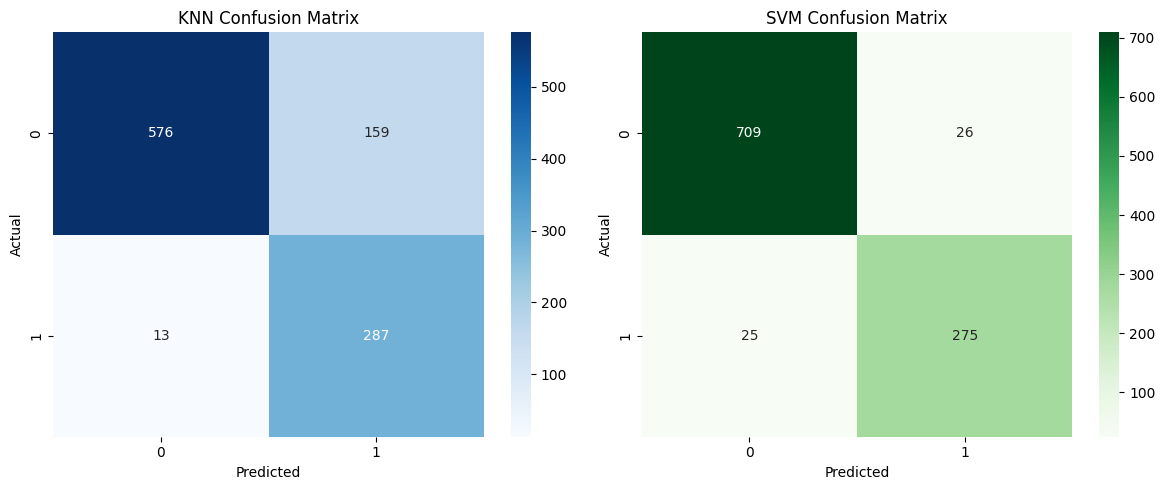

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_knn),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, y_pred_svm),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

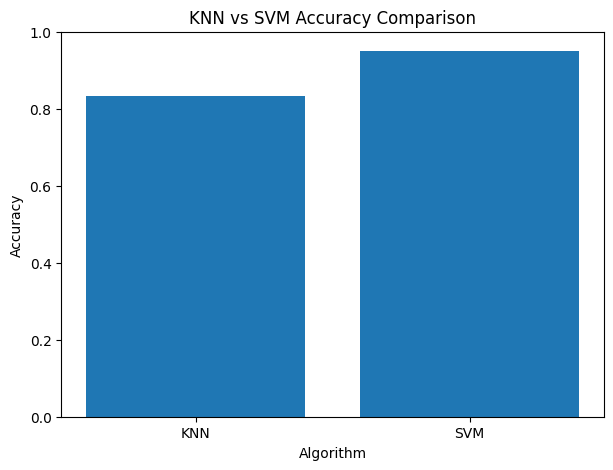

In [9]:
plt.figure(figsize=(7, 5))

plt.bar(
    results["Algorithm"],
    results["Accuracy"]
)

plt.title("KNN vs SVM Accuracy Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()